## Домашнее задание

Памперсы или пиво? Практический проект по созданию рекомендательной системы

### Цель:

Настало время поработать с данными самой большой и самой дорогой компании, занимающейся, похоже, уже всем на свете: от продажи всего и вся, до настройки облачных инфраструктур и создания роботов. Конечно же это компания Джеффа могу-купить-весь-мир Безоса - Amazon.


### Описание/Пошаговая инструкция выполнения домашнего задания:

Выберите любой понравившийся вам набор данных по ссылке https://cseweb.ucsd.edu/~jmcauley/datasets/amazon_v2/, стоит обратить внимание на раздел "Small" subsets for experimentation, где представлены не самые большие датасеты (чтобы и в память поместился, и считался недолго).

Проведите базовый EDA - распределения рейтингов, количество уникальных товаров и т.д.

Сделайте разбиение данных на train и test методом leave-one-out.

На основании вашего датасета постройте 2-3 рекомендательных модели, можно включить простой бейзлайн типа модели, рекомендующей самые популярные товары.

Оцените качество полученных рекомендаций по метрикам HR@10, MRR@10, NDCG@10, coverage.

Сделайте выводы о качестве моделей.




In [1]:
import pandas as pd
from implicit.als import AlternatingLeastSquares
from implicit.nearest_neighbours import ItemItemRecommender, CosineRecommender
from implicit.lmf import LogisticMatrixFactorization
from scipy.sparse import csr_matrix
import seaborn as sns
import matplotlib.pyplot as plt
from replay.metrics import HitRate, MRR, NDCG, Coverage, Experiment

import gzip
import json
import warnings

warnings.filterwarnings("ignore")

## Датасет

In [2]:
def parse(path):
  g = gzip.open(path, 'rb')
  for l in g:
    yield json.loads(l)

def getDF(path):
  i = 0
  df = {}
  for d in parse(path):
    df[i] = d
    i += 1
  return pd.DataFrame.from_dict(df, orient='index')

df = getDF('Video_Games_5.json.gz')

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 497577 entries, 0 to 497576
Data columns (total 12 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   overall         497577 non-null  float64
 1   verified        497577 non-null  bool   
 2   reviewTime      497577 non-null  object 
 3   reviewerID      497577 non-null  object 
 4   asin            497577 non-null  object 
 5   reviewerName    497501 non-null  object 
 6   reviewText      497419 non-null  object 
 7   summary         497468 non-null  object 
 8   unixReviewTime  497577 non-null  int64  
 9   vote            107793 non-null  object 
 10  style           289237 non-null  object 
 11  image           3634 non-null    object 
dtypes: bool(1), float64(1), int64(1), object(9)
memory usage: 46.0+ MB


In [4]:
df.head()

,overall,verified,reviewTime,reviewerID,asin,reviewerName,reviewText,summary,unixReviewTime,vote,style,image
0,5.0,True,"10 17, 2015",A1HP7NVNPFMA4N,0700026657,Ambrosia075,"This game is a bit hard to get the hang of, bu...",but when you do it's great.,1445040000,NaN,NaN,NaN
1,4.0,False,"07 27, 2015",A1JGAP0185YJI6,0700026657,travis,I played it a while but it was alright. The st...,"But in spite of that it was fun, I liked it",1437955200,NaN,NaN,NaN
2,3.0,True,"02 23, 2015",A1YJWEXHQBWK2B,0700026657,Vincent G. Mezera,ok game.,Three Stars,1424649600,NaN,NaN,NaN
3,2.0,True,"02 20, 2015",A2204E1TH211HT,0700026657,Grandma KR,"found the game a bit too complicated, not what...",Two Stars,1424390400,NaN,NaN,NaN
4,5.0,True,"12 25, 2014",A2RF5B5H74JLPE,0700026657,jon,"great game, I love it and have played it since...",love this game,1419465600,NaN,NaN,NaN


overall - rating of the product

verified - verified review

reviewTime - time of the review (raw)

reviewerID - ID of the reviewer, e.g. A2SUAM1J3GNN3B

asin - ID of the product, e.g. 0000013714

reviewerName - name of the reviewer

reviewText - text of the review

summary - summary of the review

unixReviewTime - time of the review (unix time)

vote - helpful votes of the review

style - a disctionary of the product metadata, e.g., "Format" is "Hardcover"

image - images that users post after they have received the product

### Предобработка

In [5]:
# конвертируем в дату
df.loc[:, 'reviewTime'] = pd.to_datetime(df['unixReviewTime'],unit="s")

In [6]:
df

,overall,verified,reviewTime,reviewerID,asin,reviewerName,reviewText,summary,unixReviewTime,vote,style,image
0,5.0,True,2015-10-17 00:00:00,A1HP7NVNPFMA4N,0700026657,Ambrosia075,"This game is a bit hard to get the hang of, bu...",but when you do it's great.,1445040000,NaN,NaN,NaN
1,4.0,False,2015-07-27 00:00:00,A1JGAP0185YJI6,0700026657,travis,I played it a while but it was alright. The st...,"But in spite of that it was fun, I liked it",1437955200,NaN,NaN,NaN
2,3.0,True,2015-02-23 00:00:00,A1YJWEXHQBWK2B,0700026657,Vincent G. Mezera,ok game.,Three Stars,1424649600,NaN,NaN,NaN
3,2.0,True,2015-02-20 00:00:00,A2204E1TH211HT,0700026657,Grandma KR,"found the game a bit too complicated, not what...",Two Stars,1424390400,NaN,NaN,NaN
4,5.0,True,2014-12-25 00:00:00,A2RF5B5H74JLPE,0700026657,jon,"great game, I love it and have played it since...",love this game,1419465600,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...
497572,4.0,True,2017-07-01 00:00:00,AVECM71LSZLC5,B01HGPUTCA,boris teplitskiy,not OEM but good replacement parts,Four Stars,1498867200,NaN,NaN,NaN
497573,3.0,True,2018-08-20 00:00:00,A1RS06313BL6WN,B01HH6JEOC,Tom Stopsign,Okay stuff.,Three Stars,1534723200,NaN,"{'Edition:': ' Kids Room', 'Platform:': ' PC O...",NaN
497574,3.0,True,2017-08-07 00:00:00,ACIZ77IGIX2JL,B01HH6JEOC,Era,This does add some kids room things that are v...,Only buy on sale.,1502064000,NaN,"{'Edition:': ' Kids Room', 'Platform:': ' PC O...",NaN
497575,4.0,False,2018-08-05 00:00:00,A34GG58TJ1A3SH,B01HIZF7XE,seamonkey10,I think I originally began playing Bioshock se...,"It's Okay, Nothing Profound",1533427200,NaN,"{'Edition:': ' Collection', 'Platform:': ' Xbo...",NaN


In [7]:
# удаляем дубликаты, оставляя последний по времени
df = df.sort_values('reviewTime').drop_duplicates(subset=['reviewerID', 'asin'], keep='last')

In [8]:
# Будем рассматривать только подтвержденные обзоры
df = df[df['verified']==True].reset_index(drop=True)

In [9]:
USER_COL = 'reviewerID'
ITEM_COL = 'asin'
RATING_COL = 'overall'
TIMESTAMP = 'reviewTime'

In [10]:
df

,overall,verified,reviewTime,reviewerID,asin,reviewerName,reviewText,summary,unixReviewTime,vote,style,image
0,5.0,True,1999-11-10 00:00:00,A3VWWQT4XDSBGQ,B00000K4AX,Joshua W. Fenton,"If you loved Half-Life, this is a must buy. I ...",AWESOME!,942192000,5,NaN,NaN
1,4.0,True,1999-11-24 00:00:00,A2T04VAIXSKJH2,B00002EPY1,Stefan,Delta Force 1 was a great new addition in the ...,a slower Delta Force 1 with a few new weapons,943401600,5,NaN,NaN
2,4.0,True,1999-12-28 00:00:00,A3V6Z4RCDGRC44,B00000K3DM,Lisa Shea,We waited quite a while for Dungeon Keeper 2 t...,Dungeon Keeper 2: Good & Bad,946339200,16,NaN,NaN
3,5.0,True,1999-12-29 00:00:00,AU34LBHEJ264C,B00002NDRR,JORGE ZURITA S,I'm a fan of Flight Simulator since Ver. 4.0. ...,EXCELLENT FLIGHT SIM...! ! !,946425600,NaN,NaN,NaN
4,5.0,True,2000-01-28 00:00:00,ACCUPJZUVRNT1,B00000K2YD,D. Woodruff,This is by far the BEST darn game I have playe...,Greatest Game Ever Made,949017600,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...
318806,5.0,True,2018-09-28 00:00:00,A1I1FB6YT9OV03,B01GW3POY0,Michael Otiashvili,"Everything is as should be. Fully satisfied, t...",Greatness awaits.,1538092800,NaN,"{'Edition:': ' Standard', 'Platform:': ' PlayS...",NaN
318807,5.0,True,2018-09-28 00:00:00,A1H5KNQ61FFCX2,B01GW8YDLK,khuddle,"Title says it all. This is masterpiece, period...",Best game I've played on PS4 since Uncharted 4,1538092800,2,"{'Edition:': ' Standard', 'Platform:': ' PlayS...",NaN
318808,4.0,True,2018-09-29 00:00:00,AXGJNBYPUNR2,B01FDA42PU,Christopher Affinati,Seems to be decent quality.,Solid case for a reasonable price.,1538179200,NaN,NaN,NaN
318809,5.0,True,2018-10-01 00:00:00,A1SDXNTHJ255P7,B01GW3H3U8,Rob G.,Upgrade from the original XB1 controller. It ...,It feels much better in your,1538352000,NaN,{'Edition:': ' White'},NaN


### Данные

In [11]:
print(f'Размер датасета = {df.shape[0]} \nКоличество пользователей = {df[USER_COL].nunique()} \nКоличество объектов = {df[ITEM_COL].nunique()}')

Размер датасета = 318811 
Количество пользователей = 49073 
Количество объектов = 17099


## EDA

In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 318811 entries, 0 to 318810
Data columns (total 12 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   overall         318811 non-null  float64
 1   verified        318811 non-null  bool   
 2   reviewTime      318811 non-null  object 
 3   reviewerID      318811 non-null  object 
 4   asin            318811 non-null  object 
 5   reviewerName    318751 non-null  object 
 6   reviewText      318671 non-null  object 
 7   summary         318725 non-null  object 
 8   unixReviewTime  318811 non-null  int64  
 9   vote            35883 non-null   object 
 10  style           183652 non-null  object 
 11  image           2345 non-null    object 
dtypes: bool(1), float64(1), int64(1), object(9)
memory usage: 27.1+ MB


In [13]:
df[ITEM_COL] = df[ITEM_COL].astype('str') 
df[USER_COL] = df[USER_COL].astype('str') 

### Распределение рейтингов

<Axes: >

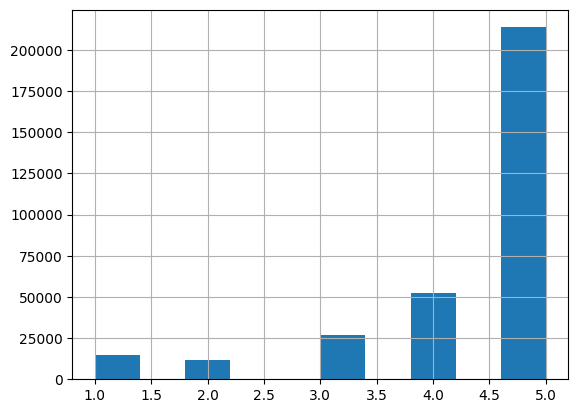

In [14]:
df[RATING_COL].hist()

### Количество пользователей давших n оценок 

<Axes: >

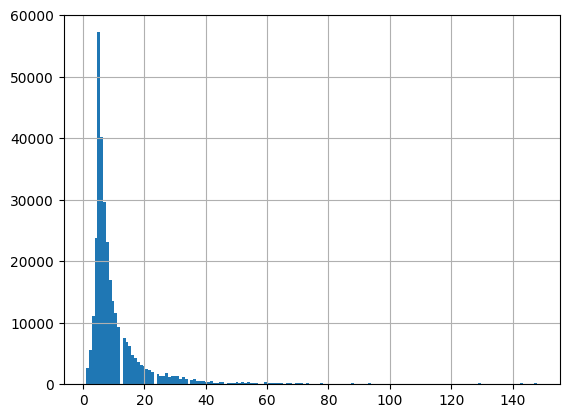

In [15]:
df.groupby(USER_COL)[USER_COL].transform('size').hist(bins=160)

### Количество товаров оцененных n пользователями 

<Axes: >

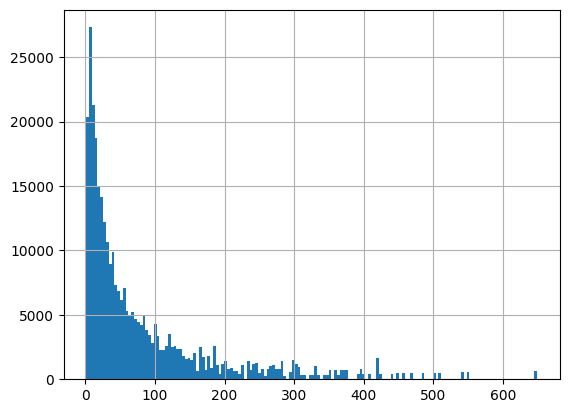

In [16]:
df.groupby(ITEM_COL)[ITEM_COL].transform('size').hist(bins=160)

## Фильтрация данных

In [17]:
def filter_data(df, user_count=3, item_count=3):
    item_counts = df.groupby(ITEM_COL)[USER_COL].count()
    pop_items = item_counts[item_counts >= user_count]
    df = df[df[ITEM_COL].isin(pop_items.index)]

    user_counts = df.groupby(USER_COL)[ITEM_COL].count()
    pop_users = user_counts[user_counts >= user_count]
    df = df[df[USER_COL].isin(pop_users.index)].copy()
    return df

Фильтруем пользователей, у которых меньше 3 товаров и товары, которые оценили менее 3 пользователей.

In [18]:
df = filter_data(df)
df.shape[0]

307917

#### Разбиение данных на train и test методом leave-one-out

In [19]:
def train_test_split(df):
  df.sort_values(by=[TIMESTAMP], inplace=True) # сортируем данные по времени
  items = df.groupby([USER_COL], sort=False)[ITEM_COL].apply(lambda x: list(x)).reset_index() # создаем список items для каждого пользователя
  ratings = df.groupby([USER_COL], sort=False)[RATING_COL].apply(lambda x: list(x)).reset_index() # создаем список рейтингов для каждого пользователя
  df = items.merge(ratings)

  train = pd.DataFrame(df[USER_COL])
  train[ITEM_COL] = df[ITEM_COL].apply(lambda x: x[:-1]) # отделяем все кроме последнего item в train
  train[RATING_COL] = df[RATING_COL].apply(lambda x: x[:-1]) # отделяем все кроме последнего рейтинги в train
  train = train.explode([ITEM_COL, RATING_COL])

  test = pd.DataFrame(df[USER_COL])
  test[ITEM_COL] = df[ITEM_COL].apply(lambda x: x[-1:]) # отделяем последний item в test
  test[RATING_COL] = df[RATING_COL].apply(lambda x: x[-1:]) # отделяем последний рейтинг в test
  test = test.explode([ITEM_COL, RATING_COL])

  test.reset_index(drop=True, inplace=True)
  train.reset_index(drop=True, inplace=True)
  
  return train, test

In [20]:
train, test = train_test_split(df)

In [21]:
train

,reviewerID,asin,overall
0,A3VWWQT4XDSBGQ,B00000K4AX,5.0
1,A3VWWQT4XDSBGQ,B000059O8B,5.0
2,A3VWWQT4XDSBGQ,B000X418EU,3.0
3,A3V6Z4RCDGRC44,B00000K3DM,4.0
4,A3V6Z4RCDGRC44,B00004Y57G,5.0
...,...,...,...
264461,A31FCTAAUTA1Y0,B01D9T0BAC,5.0
264462,A31FCTAAUTA1Y0,B01BLSZHJI,5.0
264463,A2EOHW4YW16820,B01GKGVI8U,5.0
264464,A2EOHW4YW16820,B01GW3NY5Q,4.0


In [22]:
test

,reviewerID,asin,overall
0,A3VWWQT4XDSBGQ,B000WINB56,3.0
1,A3V6Z4RCDGRC44,B0002IQOOQ,5.0
2,AU34LBHEJ264C,B0007N33IQ,5.0
3,ANVBALAY6KAQT,B00DFT92EI,4.0
4,A3E610EXHOMIO6,B00M8RM08I,5.0
...,...,...,...
43446,A3ICVV2J3H45OC,B013HJ71V6,5.0
43447,AUBX4YM2LT6RN,B00YOB78HE,5.0
43448,A13VJZFVJHTTP7,B017W17G1U,5.0
43449,A31FCTAAUTA1Y0,B00KM66ULK,5.0


Будем предсказывать только товары с максимальным рейтингом

In [23]:
test = test[test[RATING_COL]==5.0]

In [24]:
test

,reviewerID,asin,overall
1,A3V6Z4RCDGRC44,B0002IQOOQ,5.0
2,AU34LBHEJ264C,B0007N33IQ,5.0
4,A3E610EXHOMIO6,B00M8RM08I,5.0
6,A3SP37JLGH5KFY,B00004S99S,5.0
7,ATMQ311QH86HN,B00ZMBMO06,5.0
...,...,...,...
43444,A1HQB9C9453N6Q,B00Z0UWWYC,5.0
43446,A3ICVV2J3H45OC,B013HJ71V6,5.0
43447,AUBX4YM2LT6RN,B00YOB78HE,5.0
43448,A13VJZFVJHTTP7,B017W17G1U,5.0


## Построение моделей

In [25]:
# маппинг id в индексы
def get_mapping(train_data):
    user_ids = sorted(train_data[USER_COL].unique().tolist())
    item_ids = sorted(train_data[ITEM_COL].unique().tolist())

    n_users = len(user_ids)
    n_items = len(item_ids)

    user_idx = range(n_users)
    item_idx = range(n_items)

    user_mapping = dict(zip(user_ids, user_idx)) # {user_id: user_ind}
    item_mapping = dict(zip(item_ids, item_idx)) # {item_id: item_ind}
    return user_mapping, item_mapping

In [26]:
user_mapping, item_mapping = get_mapping(train)
train[USER_COL] = train[USER_COL].map(user_mapping)
test[USER_COL] = test[USER_COL].map(user_mapping)
train[ITEM_COL] = train[ITEM_COL].map(item_mapping)
test[ITEM_COL] = test[ITEM_COL].map(item_mapping)

In [27]:
train

,reviewerID,asin,overall
0,33212,154,5.0
1,33212,1181,5.0
2,33212,5291,3.0
3,32976,151,4.0
4,32976,1094,5.0
...,...,...,...
264461,23343,15113,5.0
264462,23343,14985,5.0
264463,16176,15363,5.0
264464,16176,15428,4.0


In [28]:
test

,reviewerID,asin,overall
1,32976,2648.0,5.0
2,41538,2856.0,5.0
4,27464,12768.0,5.0
6,32164,803.0,5.0
7,41403,14013.0,5.0
...,...,...,...
43444,5745,13913.0,5.0
43446,28809,14231.0,5.0
43447,41617,13866.0,5.0
43448,1306,14698.0,5.0


In [29]:
test_users = test[USER_COL].values # пользователи из тестовой выборки

In [30]:
test_users

array([32976, 41538, 27464, ..., 41617,  1306, 23343], dtype=int64)

#### Создаем sparse матрицу

In [31]:
values = train[RATING_COL].astype(float).values
rows = train[USER_COL].values
cols = train[ITEM_COL].values

train_sparse = csr_matrix((values, (rows, cols))) # создаем sparse матрицу

Посмотрим, насколько разрежена полученная матрица.

In [32]:
matrix_size = train_sparse.shape[0] * train_sparse.shape[1] # размер матрицы взаимодействий
num_reviews = len(train_sparse.nonzero()[0]) # количество интеракций
sparsity = 100 * (1 - (num_reviews/matrix_size))
sparsity

99.96077000156636

In [33]:
num_reviews

264466

#### Рекомендации

In [34]:
def get_recs(algo, test_users, interactions_sparse, k=10):
    items, values = algo.recommend(
        test_users,                                 
        interactions_sparse[test_users],           
        N=k,                                        
        filter_already_liked_items=True            
        )

    # составим датафрейм с рекомендованными товарами
    recs = pd.DataFrame({
        USER_COL: test_users,
        ITEM_COL: items.tolist(),
        "score": values.tolist()
    })
    recs = recs.explode([ITEM_COL, "score"])

    return recs

#### Метрики

In [35]:
K = [10]
metrics = Experiment(
    [MRR(K),
     HitRate(K),
     NDCG(K),
     Coverage(K)],
    test,
    train,
    query_column=USER_COL,
    item_column=ITEM_COL,
    rating_column="score",
)

##  itemKNN

In [36]:
algo = ItemItemRecommender(K=5)
algo.fit((train_sparse).astype('double'))

  0%|          | 0/15515 [00:00<?, ?it/s]

In [37]:
recs = get_recs(algo, test_users, train_sparse)
recs

,reviewerID,asin,score
0,32976,4128,7435.0
0,32976,6595,6553.0
0,32976,3771,5228.0
0,32976,5381,4950.0
0,32976,315,4785.0
...,...,...,...
28756,23343,15427,500.0
28756,23343,14493,375.0
28756,23343,14027,375.0
28756,23343,13858,375.0


In [38]:
metrics.add_result("itemKNN", recs)

## Cosine

In [39]:
algo = CosineRecommender(K=5)
algo.fit((train_sparse).astype('double'))

  0%|          | 0/15515 [00:00<?, ?it/s]

In [40]:
recs = get_recs(algo, test_users, train_sparse)
recs

,reviewerID,asin,score
0,32976,315,3.014043
0,32976,578,2.08084
0,32976,62,2.029718
0,32976,4128,1.968821
0,32976,972,1.698416
...,...,...,...
28756,23343,7090,0.90167
28756,23343,14720,0.859518
28756,23343,15196,0.855883
28756,23343,10641,0.840138


In [41]:
metrics.add_result("Cosine", recs)

## ALS

In [42]:
algo = AlternatingLeastSquares(factors=50, regularization=0.1, iterations=50, use_gpu=False)
algo.fit((train_sparse).astype('double'))

  0%|          | 0/50 [00:00<?, ?it/s]

In [43]:
recs = get_recs(algo, test_users, train_sparse)
recs

,reviewerID,asin,score
0,32976,6595,1.126405
0,32976,5381,0.790767
0,32976,4128,0.752226
0,32976,6908,0.733457
0,32976,5378,0.640562
...,...,...,...
28756,23343,12739,0.217833
28756,23343,12150,0.203972
28756,23343,10960,0.202293
28756,23343,14527,0.194815


In [44]:
metrics.add_result("ALS", recs)

## Оценка качества

In [45]:
metrics.results

,MRR@10,HitRate@10,NDCG@10,Coverage@10
itemKNN,0.052987,0.116320,0.067757,0.606381
Cosine,0.036944,0.070626,0.044805,0.914212
ALS,0.042237,0.095872,0.054719,0.053110


## Выводы

Если оценивать по HR, то лучший алгоритм itemKNN, затем идет ALS. 

Cosine имеет худший результат, много дает неточных рекомендаций, но за счет более высокого Coverage может предлагать больше товаров на любителя.